Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.
100%|██████████| 9/9 [00:00<00:00, 77.27it/s]


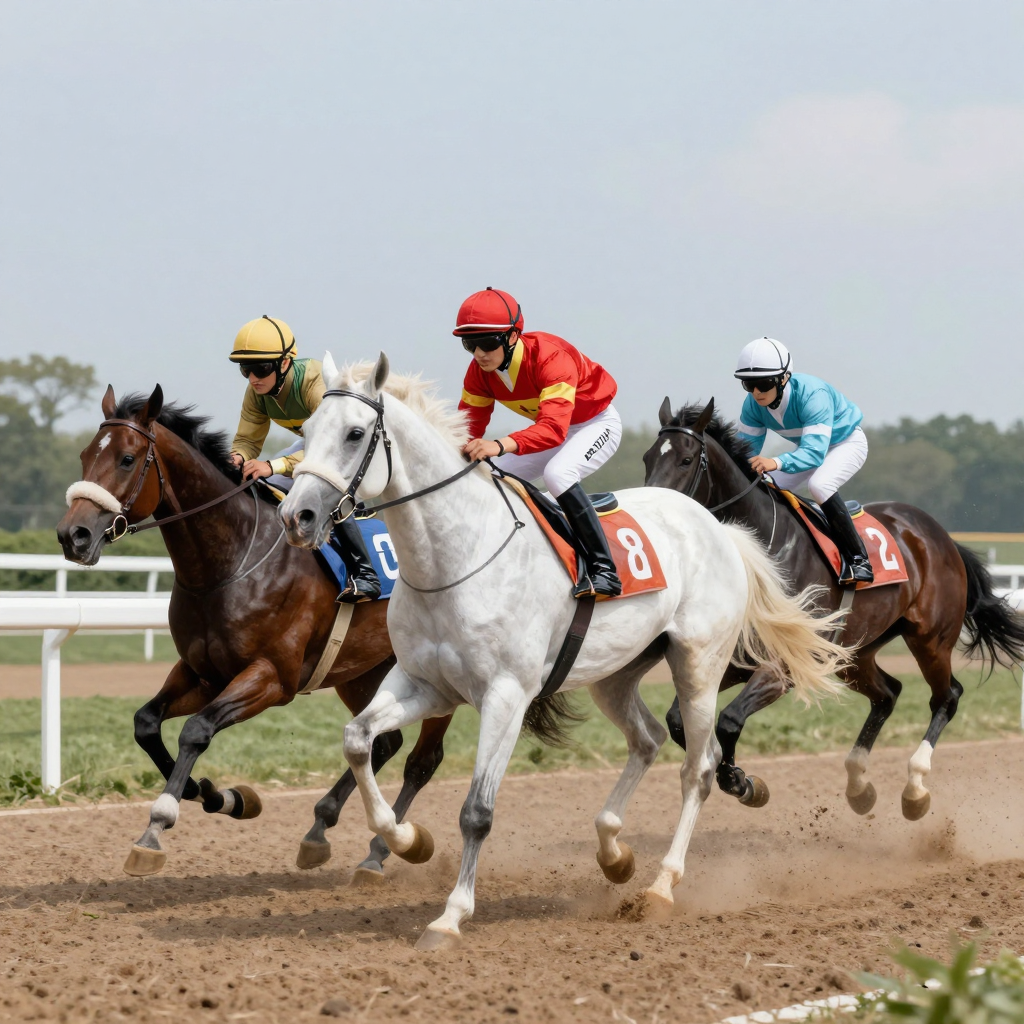

In [2]:
import torch
from diffusers import ZImagePipeline

zimage_pipe = ZImagePipeline.from_pretrained("Tongyi-MAI/Z-Image-Turbo", dtype=torch.bfloat16)
zimage_pipe = zimage_pipe.to('mps')
prompt = "아크릴 그림, 경마장에서 시합중인 5마리의 말들, 백마 3마리, 흑마 2마리"
image = zimage_pipe(
    prompt=prompt,
    height=1024,
    width=1024,
    num_inference_steps=9,  # 모델 카드 기준으로 9로 두면 트랜스포머를 8번 호출한다.
    guidance_scale=0.0,     # Turbo는 CFG 없이 쓰도록 증류되었으므로 0으로 둔다.
    generator=torch.Generator('mps').manual_seed(0),
).images[0]
image